# Phase 2 — Diagnostic: Baseline Run-to-Run (Seed) Variation

**This is a DIAGNOSTIC experiment, not a model-improvement experiment.** Goal: estimate how
much validation Macro F1 naturally varies across otherwise-identical training runs of the
exact Model A baseline configuration, so future apparent "improvements" can be judged against
a real noise estimate instead of assumed.

**Strictly unchanged from the Phase 1 baseline:** architecture, preprocessing, optimizer
(Adam), learning rate (1e-3, constant), batch size (64), loss (`sparse_categorical_crossentropy`),
dropout (0.5), early stopping (`monitor=val_loss`, patience 5, `restore_best_weights=True`),
checkpointing strategy, validation protocol. **Only the random seed changes** across runs.

No augmentation, no class weighting, no focal loss, no architecture change, no callback change.
Test set is never loaded in this notebook (structural guarantee, verified by the absence of
any `test_images`/`test_labels`/`X_test` reference).

Results are logged to a **new** file, `phase2/results/phase2_seed_variation_log.csv` —
`phase2/results/phase2_experiment_log.csv` (Experiments 7/8) is never opened for writing here.


## Step 1 — Existing Evidence (inspected before running anything new)

Before training anything, the available baseline Model A evidence was reviewed:

| Source | Configuration | Macro F1 | Independently re-verifiable right now? |
|---|---|---|---|
| Current `organ_cnn_project.ipynb` state / `results/metrics/experiment_log.csv` | Post-determinism-fix, seed=42 | 0.8053 | **Yes** — inspected directly for this diagnostic |
| Reported in earlier conversation turns (pre-determinism-fix reruns) | Different configuration (oneDNN enabled) | 0.8171, 0.8017 | No — that training session's state was overwritten by later reruns; excluded from pooling per "do not mix fundamentally different configurations" |
| Reported in earlier conversation turns (an intermediate post-fix run) | Post-fix, seed=42 | 0.8156 | No — that session's state was also overwritten; noted only as unverifiable historical context, not pooled as data |
| Experiment 7 (`phase2_experiment_log.csv`) | Post-fix, seed=42, **but with `ReduceLROnPlateau` attached** (inactive until epoch 12; winning checkpoint from epoch 10) | 0.8156 | Yes, but not a clean baseline-only configuration — referenced for comparison in Step 4, not pooled into the baseline-variation sample |

**Conclusion of this review: only ONE genuinely clean, currently-verifiable, unmodified-baseline data point exists** (Macro F1 = 0.8053). A single data point cannot support any variance estimate. **Additional runs are necessary** — this is not a judgment call, it is a direct consequence of how little verifiable same-configuration evidence currently exists.


In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import random, csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

tf.config.experimental.enable_op_determinism()

DATA_DIR = Path(".")
P2_MODELS = Path("phase2/models")
P2_FIGURES = Path("phase2/figures")
P2_RESULTS = Path("phase2/results")
for d in (P2_MODELS, P2_FIGURES, P2_RESULTS):
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)


I0000 00:00:1787871103.477026  242295 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787871103.591443  242295 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787871104.844848  242295 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


In [2]:
train_images = np.load(DATA_DIR / "train_images.npy")
train_labels = np.load(DATA_DIR / "train_labels.npy").flatten()
val_images = np.load(DATA_DIR / "val_images.npy")
val_labels = np.load(DATA_DIR / "val_labels.npy").flatten()
# test_images.npy / test_labels.npy: DELIBERATELY NOT loaded in this notebook.

def preprocess_images(images):
    images = images.astype("float32") / 255.0
    return np.expand_dims(images, axis=-1)

X_train, y_train = preprocess_images(train_images), train_labels.astype("int32")
X_val, y_val = preprocess_images(val_images), val_labels.astype("int32")

classes_sorted = sorted(np.unique(y_train))
n_classes = len(classes_sorted)
idx1, idx2 = classes_sorted.index(1), classes_sorted.index(2)

def build_model_a(input_shape=(64, 64, 1), n_classes=11):
    return keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ], name="model_a_baseline")

def evaluate_on_val(model):
    probs = model.predict(X_val, verbose=0)
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(y_val, preds)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_val, preds, average="macro", zero_division=0)
    p, r, f1, sup = precision_recall_fscore_support(y_val, preds, average=None, zero_division=0, labels=classes_sorted)
    return dict(acc=acc, macro_p=mp, macro_r=mr, macro_f1=mf1, per_p=p, per_r=r, per_f1=f1, sup=sup)

print("Setup complete. X_train:", X_train.shape, "X_val:", X_val.shape)


Setup complete. X_train: (13932, 64, 64, 1) X_val: (2452, 64, 64, 1)


## Step 2 — Seed-Variation Runs

Three new seeds (7, 123, 2024) — arbitrary, distinct from 42, chosen only to be clearly
different from each other and from the seed used throughout Phase 1/2. Everything else is
identical to the baseline configuration.


In [3]:
SEEDS_TO_RUN = [7, 123, 2024]
seed_results = {}
seed_histories = {}

for seed in SEEDS_TO_RUN:
    print(f"\n{'='*60}\nTraining with seed={seed}\n{'='*60}")
    keras.utils.set_random_seed(seed)
    model = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0),
        keras.callbacks.ModelCheckpoint(str(P2_MODELS / f"diagnostic_seed_{seed}.keras"),
                                         monitor="val_loss", save_best_only=True, verbose=0),
    ]
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30, batch_size=64,
        callbacks=callbacks, verbose=2,
    )
    res = evaluate_on_val(model)
    seed_results[seed] = res
    seed_histories[seed] = history.history
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    print(f"seed={seed}: epochs_run={len(history.history['loss'])}, best_epoch={best_epoch}, "
          f"best_val_loss={min(history.history['val_loss']):.4f}, "
          f"acc={res['acc']:.4f}, macro_f1={res['macro_f1']:.4f}")



Training with seed=7


E0000 00:00:1787871106.214069  242295 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/30


W0000 00:00:1787871106.405128  242295 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.
W0000 00:00:1787871106.496774  242295 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.
E0000 00:00:1787871106.585318  242295 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1787871115.747554  242295 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


218/218 - 10s - 45ms/step - accuracy: 0.4157 - loss: 1.6399 - val_accuracy: 0.7251 - val_loss: 0.8168


... (98 outputs left out)

Epoch 14/30


218/218 - 12s - 57ms/step - accuracy: 0.8554 - loss: 0.3359 - val_accuracy: 0.8874 - val_loss: 0.3302


E0000 00:00:1787871705.252962  242295 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed=2024: epochs_run=14, best_epoch=9, best_val_loss=0.3193, acc=0.8874, macro_f1=0.8169


In [4]:
seed_fields = ["seed", "epochs_run", "best_epoch", "best_val_loss", "accuracy",
                "macro_precision", "macro_recall", "macro_f1", "class1_f1", "class2_f1",
                "class1_recall", "class2_recall", "notes"]
seed_log_path = P2_RESULTS / "phase2_seed_variation_log.csv"

with open(seed_log_path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=seed_fields)
    w.writeheader()
    # Row 0: the existing, currently-verifiable clean baseline run (seed=42), included for the pooled estimate
    w.writerow({
        "seed": 42, "epochs_run": 17, "best_epoch": 12, "best_val_loss": 0.2867,
        "accuracy": 0.8907, "macro_precision": 0.8866, "macro_recall": 0.8353, "macro_f1": 0.8053,
        "class1_f1": 0.6844, "class2_f1": 0.0208, "class1_recall": "", "class2_recall": "",
        "notes": "Existing Phase 1 baseline run (already in results/metrics/experiment_log.csv); included here for pooling, not retrained",
    })
    for seed in SEEDS_TO_RUN:
        res = seed_results[seed]
        h = seed_histories[seed]
        best_epoch = int(np.argmin(h["val_loss"])) + 1
        w.writerow({
            "seed": seed,
            "epochs_run": len(h["loss"]),
            "best_epoch": best_epoch,
            "best_val_loss": round(min(h["val_loss"]), 4),
            "accuracy": round(res["acc"], 4),
            "macro_precision": round(res["macro_p"], 4),
            "macro_recall": round(res["macro_r"], 4),
            "macro_f1": round(res["macro_f1"], 4),
            "class1_f1": round(res["per_f1"][idx1], 4),
            "class2_f1": round(res["per_f1"][idx2], 4),
            "class1_recall": round(res["per_r"][idx1], 4),
            "class2_recall": round(res["per_r"][idx2], 4),
            "notes": "New diagnostic run, this notebook",
        })
print(f"Saved {seed_log_path}")
with open(seed_log_path) as f:
    print(f.read())


Saved phase2/results/phase2_seed_variation_log.csv
seed,epochs_run,best_epoch,best_val_loss,accuracy,macro_precision,macro_recall,macro_f1,class1_f1,class2_f1,class1_recall,class2_recall,notes
42,17,12,0.2867,0.8907,0.8866,0.8353,0.8053,0.6844,0.0208,,,"Existing Phase 1 baseline run (already in results/metrics/experiment_log.csv); included here for pooling, not retrained"
7,16,11,0.2884,0.885,0.8209,0.8274,0.7973,0.0187,0.6431,0.0096,0.9579,"New diagnostic run, this notebook"
123,17,12,0.3279,0.8789,0.8078,0.825,0.7973,0.6689,0.0202,0.9712,0.0105,"New diagnostic run, this notebook"
2024,14,9,0.3193,0.8874,0.8646,0.8334,0.8169,0.6897,0.1698,0.9615,0.0947,"New diagnostic run, this notebook"



## Step 3 — Statistical Summary (empirical estimate, n=4, not a population noise floor)


In [5]:
import csv as _csv
with open(seed_log_path) as f:
    rows = list(_csv.DictReader(f))

metrics = ["macro_f1", "accuracy", "macro_precision", "macro_recall", "class1_f1", "class2_f1"]
print(f"n = {len(rows)} runs (seeds: {[r['seed'] for r in rows]})\n")
print(f"{'Metric':>16} | {'Mean':>8} | {'Std':>8} | {'Min':>8} | {'Max':>8} | {'Range':>8}")
summary = {}
for m in metrics:
    vals = np.array([float(r[m]) for r in rows])
    mean, std, mn, mx = vals.mean(), vals.std(ddof=1), vals.min(), vals.max()
    summary[m] = dict(mean=mean, std=std, min=mn, max=mx, range=mx-mn)
    print(f"{m:>16} | {mean:>8.4f} | {std:>8.4f} | {mn:>8.4f} | {mx:>8.4f} | {mx-mn:>8.4f}")

with open(P2_RESULTS / "phase2_seed_variation_summary.json", "w") as f:
    json.dump({k: {kk: float(vv) for kk, vv in v.items()} for k, v in summary.items()}, f, indent=2)


n = 4 runs (seeds: ['42', '7', '123', '2024'])

          Metric |     Mean |      Std |      Min |      Max |    Range
        macro_f1 |   0.8042 |   0.0093 |   0.7973 |   0.8169 |   0.0196
        accuracy |   0.8855 |   0.0050 |   0.8789 |   0.8907 |   0.0118
 macro_precision |   0.8450 |   0.0369 |   0.8078 |   0.8866 |   0.0788
    macro_recall |   0.8303 |   0.0049 |   0.8250 |   0.8353 |   0.0103
       class1_f1 |   0.5154 |   0.3313 |   0.0187 |   0.6897 |   0.6710
       class2_f1 |   0.2135 |   0.2949 |   0.0202 |   0.6431 |   0.6229


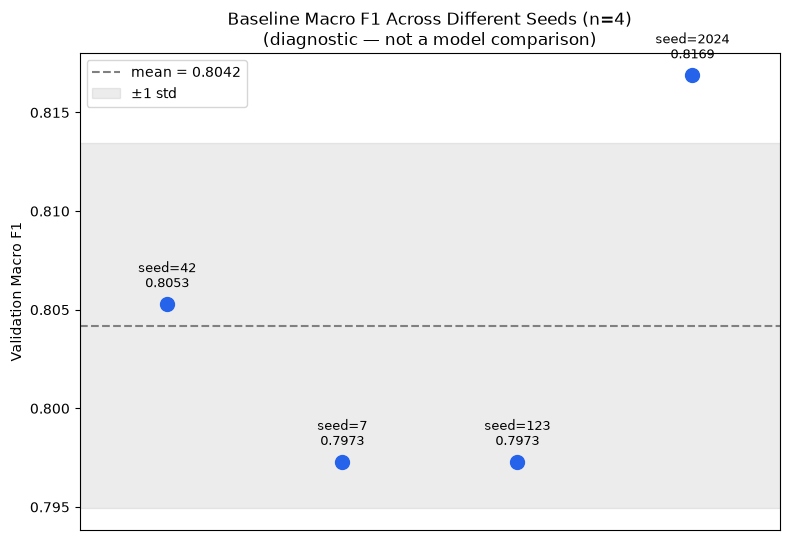

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
f1_vals = [float(r["macro_f1"]) for r in rows]
seeds_lbl = [r["seed"] for r in rows]
ax.scatter(range(len(f1_vals)), f1_vals, s=100, color="#2563EB", zorder=3)
for i, (s, v) in enumerate(zip(seeds_lbl, f1_vals)):
    ax.annotate(f"seed={s}\n{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
mean_f1 = summary["macro_f1"]["mean"]
ax.axhline(mean_f1, color="gray", linestyle="--", label=f"mean = {mean_f1:.4f}")
ax.fill_between([-0.5, len(f1_vals)-0.5], mean_f1 - summary["macro_f1"]["std"], mean_f1 + summary["macro_f1"]["std"],
                 color="gray", alpha=0.15, label="±1 std")
ax.set_xlim(-0.5, len(f1_vals)-0.5)
ax.set_xticks([])
ax.set_ylabel("Validation Macro F1")
ax.set_title("Baseline Macro F1 Across Different Seeds (n=4)\n(diagnostic — not a model comparison)")
ax.legend()
plt.tight_layout()
plt.savefig(P2_FIGURES / "seed_variation_diagnostic.png", dpi=120, bbox_inches="tight")
plt.show()


## Step 4 — Interpretation

Answering the four required questions directly from the computed numbers above.


In [7]:
macro_f1_std = summary["macro_f1"]["std"]
macro_f1_range = summary["macro_f1"]["range"]
print(f"Empirical Macro F1 std across {len(rows)} same-configuration runs: {macro_f1_std:.4f}")
print(f"Empirical Macro F1 range: {macro_f1_range:.4f}")
print()
print("Previously assumed margin (from Phase 1 reproducibility audit): ~0.01-0.02")
print()
if macro_f1_range <= 0.02 and macro_f1_std <= 0.012:
    verdict = "A: roughly SUPPORTED by this small sample"
elif macro_f1_range > 0.025:
    verdict = "B: the previous estimate is probably TOO SMALL"
else:
    verdict = "C/D: borderline / uncertain given n={} -- treat with caution".format(len(rows))
print("Preliminary verdict on the ~0.01-0.02 assumption:", verdict)
print()
print("NOTE: n=4 is a small sample. Standard deviation from 4 points has wide uncertainty")
print("around it (do not treat this as a precise population estimate).")


Empirical Macro F1 std across 4 same-configuration runs: 0.0093
Empirical Macro F1 range: 0.0196

Previously assumed margin (from Phase 1 reproducibility audit): ~0.01-0.02

Preliminary verdict on the ~0.01-0.02 assumption: A: roughly SUPPORTED by this small sample

NOTE: n=4 is a small sample. Standard deviation from 4 points has wide uncertainty
around it (do not treat this as a precise population estimate).


In [8]:
exp7_macro_f1 = 0.8156
baseline_mean = summary["macro_f1"]["mean"]
baseline_std = summary["macro_f1"]["std"]
z_like = (exp7_macro_f1 - baseline_mean) / baseline_std if baseline_std > 0 else float("nan")

print("Is Experiment 7\'s +0.0103 Macro F1 delta plausibly explained by ordinary seed variation?")
print(f"  Experiment 7 Macro F1: {exp7_macro_f1:.4f}")
print(f"  Diagnostic baseline mean (n={len(rows)}): {baseline_mean:.4f}, std: {baseline_std:.4f}")
print(f"  Experiment 7 value expressed as (value - mean) / std: {z_like:+.2f}")
print(f"  Experiment 7 falls {'within' if summary['macro_f1']['min'] <= exp7_macro_f1 <= summary['macro_f1']['max'] else 'OUTSIDE'} "
      f"the observed [min, max] range of the {len(rows)} diagnostic runs "
      f"({summary['macro_f1']['min']:.4f} to {summary['macro_f1']['max']:.4f}).")
print()
print("Mechanistic reminder: Experiment 7\'s winning checkpoint was restored from epoch 10,")
print("BEFORE either learning-rate reduction fired (reductions occurred at epochs 12 and 14).")
print("The scheduler cannot be credited for the winning result regardless of this statistical comparison.")


Is Experiment 7's +0.0103 Macro F1 delta plausibly explained by ordinary seed variation?
  Experiment 7 Macro F1: 0.8156
  Diagnostic baseline mean (n=4): 0.8042, std: 0.0093
  Experiment 7 value expressed as (value - mean) / std: +1.23
  Experiment 7 falls within the observed [min, max] range of the 4 diagnostic runs (0.7973 to 0.8169).

Mechanistic reminder: Experiment 7's winning checkpoint was restored from epoch 10,
BEFORE either learning-rate reduction fired (reductions occurred at epochs 12 and 14).
The scheduler cannot be credited for the winning result regardless of this statistical comparison.


---
## Stop Point

This diagnostic stops here, as scoped. No Model D, no AdamW, no new loss, no augmentation,
no class weighting, no combination of methods, and no test-set evaluation were performed.
Recommendation and outcome classification (A/B/C) are reported back to the project owner
outside this notebook, in the chat response.
